# Credit Risk

32k+ rows of data

[Dataset Source](https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data)

#### 🎯 Objectives
* Train a model that can predict whether a client will default on a current loan.
* Evaluate the variables that most lend to a client defaulting - SHAP


## 1. Importing

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tqdm as notebook_tqdm
from catboost import CatBoostClassifier
from helper import *
from imblearn.ensemble import BalancedRandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from xgboost import XGBClassifier

sns.set_style("darkgrid")
sns.set_theme(
    "notebook",
    rc={
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.titlesize": 16,
        "figure.titleweight": "bold",
    },
)
sns.set_palette(["mediumseagreen", "indianred"])

c:\Users\giddy\Desktop\projects\credit-risk\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_import = pd.read_csv("data/credit_risk_dataset.csv")
df = df_import.copy()
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.shape

(32581, 12)

## Data Audit & Cleaning

Styling & naming choice improvements:
* removing "`person_`" prefix from variable names
* Clarifying and/or shortening variable names
    * "`emp_length`": "`employment_length`", "`cb_default_on_file`": "`historical_default`"
* Mapping "Y" / "N" to 0 or 1
* Moving history of default `historical_default` to 2nd last column; and
* Moving target variable `loan_status` to last column

In [ ]:
df = df.rename(columns=lambda col: col.replace("person_", ""))

df = df.rename(
    columns={
        "home_ownership": "ownership_type",
        "emp_length": "employment_length",
        "loan_amnt": "loan_amt",
        "loan_percent_income": "loan_pct_income",
        "cb_default_on_file": "historical_default",
        "cb_cred_hist_length": "cred_history_length",
    }
)

df["historical_default"] = df["historical_default"].map({"N": 0, "Y": 1})

columns = [
    col
    for col in df.columns
    if col not in ["employment_length", "historical_default", "loan_status"]
]
columns.insert(2, "employment_length")
columns += ["historical_default", "loan_status"]
df = df[columns]
df.head()

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1
1,21,9600,5.0,OWN,EDUCATION,B,1000,11.14,0.10,2,0,0
2,25,9600,1.0,MORTGAGE,MEDICAL,C,5500,12.87,0.57,3,0,1
3,23,65500,4.0,RENT,MEDICAL,C,35000,15.23,0.53,2,0,1
4,24,54400,8.0,RENT,MEDICAL,C,35000,14.27,0.55,4,1,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  32581 non-null  int64  
 1   income               32581 non-null  int64  
 2   employment_length    31686 non-null  float64
 3   ownership_type       32581 non-null  str    
 4   loan_intent          32581 non-null  str    
 5   loan_grade           32581 non-null  str    
 6   loan_amt             32581 non-null  int64  
 7   loan_int_rate        29465 non-null  float64
 8   loan_pct_income      32581 non-null  float64
 9   cred_history_length  32581 non-null  int64  
 10  historical_default   32581 non-null  int64  
 11  loan_status          32581 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 3.0 MB


Feature Name	Description
person_age	Age
person_income	Annual Income
person_home_ownership	Home ownership
person_emp_length	Employment length (in years)
loan_intent	Loan intent
loan_grade	Loan grade
loan_amnt	Loan amount
loan_int_rate	Interest rate
loan_status	Loan status (0 is non default 1 is default)
loan_percent_income	Percent income
cb_person_default_on_file	Historical default
cb_preson_cred_hist_length	Credit history length

#### Nulls & Duplicates

In [6]:
df.isna().sum()[df.isna().sum() > 0]

employment_length     895
loan_int_rate        3116
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(165)

⚠️ The dataset contains null values and duplicate records.
- Null values: Will later be addressed during the preprocessing stage.
- Duplicate records: Will now be investigated further to determine whether removal is necessary:

In [8]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10)

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
15944,21,8088,NaN,RENT,MEDICAL,C,1200,15.23,0.15,2,1,0
16835,21,8088,NaN,RENT,MEDICAL,C,1200,15.23,0.15,2,1,0
2431,21,15600,0.0,RENT,MEDICAL,A,2800,7.40,0.18,4,0,1
17758,21,15600,0.0,RENT,MEDICAL,A,2800,7.40,0.18,4,0,1
2498,21,18000,0.0,RENT,DEBTCONSOLIDATION,A,3000,7.90,0.17,2,0,1
17601,21,18000,0.0,RENT,DEBTCONSOLIDATION,A,3000,7.90,0.17,2,0,1
1778,21,20000,0.0,RENT,MEDICAL,A,2000,NaN,0.10,3,0,0
17642,21,20000,0.0,RENT,MEDICAL,A,2000,NaN,0.10,3,0,0
740,21,21600,NaN,OWN,VENTURE,A,7125,6.99,0.33,3,0,0
17283,21,21600,NaN,OWN,VENTURE,A,7125,6.99,0.33,3,0,0


* These duplicate rows show the same data, but could be different individuals and valid observations, especially given the limited granularity of the variables and the absence of a unique identifier. (It is plausible that people with the same age, income, loan type, etc. show as duplicates but are in fact different individuals.) 

* They do not appear to result from data integrity or encoding issues, such as consecutive records being duplicated due as observed by the disparity in index.

> There is insufficient evidence to classify these records as actual duplicates. Therefore, they will be **retained to avoid unintentionally removing valid observations.**

In [ ]:
cat_cols = ["ownership_type", "loan_intent", "loan_grade"]

target_col = ["loan_status"]

num_cols = (
    df.select_dtypes(include="number")
    .columns.drop(target_col, errors="ignore")
    .tolist()
)

Categorical Columns 

In [10]:
for col in cat_cols:
    print(f"{df[col].value_counts()}\n")

ownership_type
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64



In [ ]:
df["loan_intent"] = df["loan_intent"].replace(
    {"DEBTCONSOLIDATION": "DEBT CONSOLIDATION", "HOMEIMPROVEMENT": "HOME IMPROVEMENT"}
)

✅ No data integrity issues seem to be in our 3 categorical string columns. No spelling or input errors except missing spaces for readability

In [ ]:
grade_map = {g: i for i, g in enumerate("ABCDEFG", start=1)}
df["loan_grade_num"] = df["loan_grade"].map(grade_map)

#### Numerical Columns

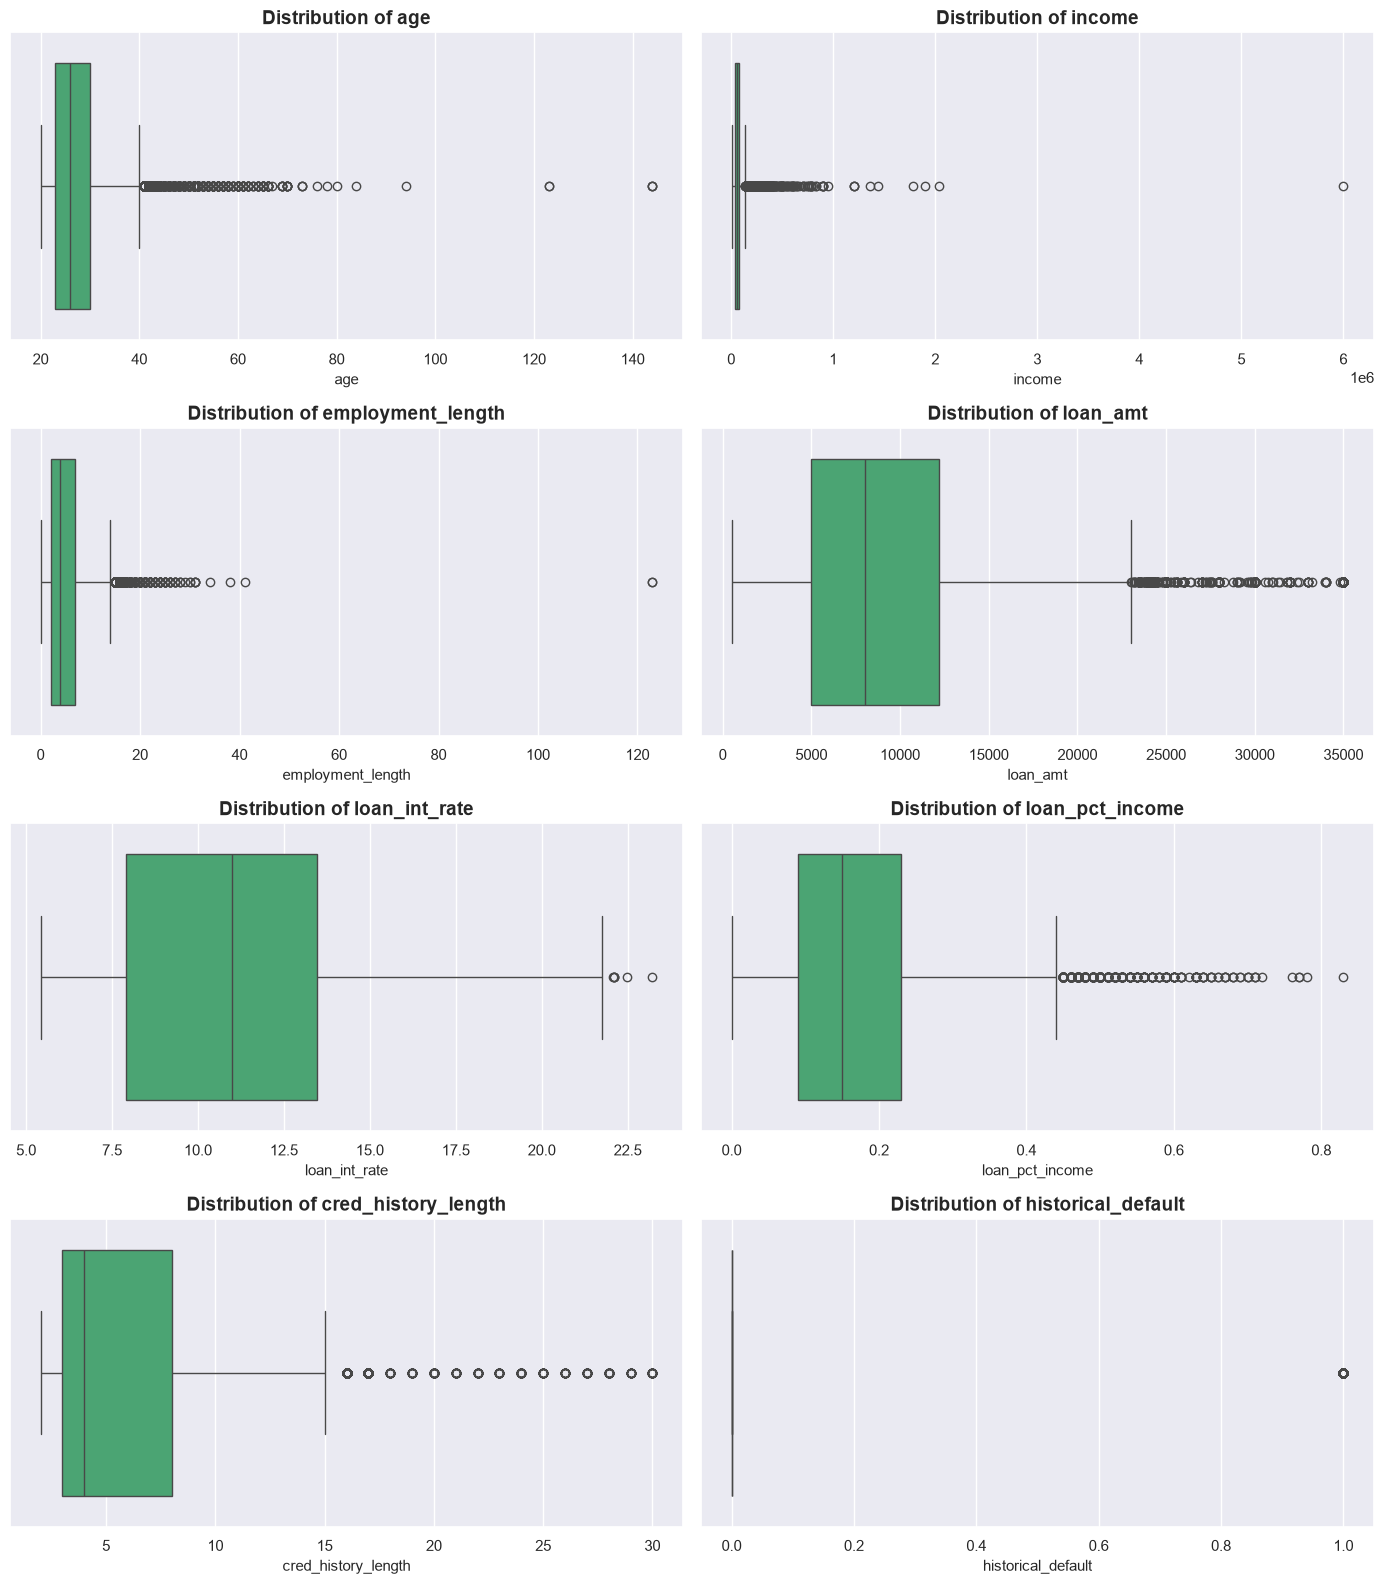

In [ ]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=2,
    figsize=(14, 4 * math.ceil(len(num_cols) / 2)),
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

✅ No negative values  
✅ Adult ages  

⚠️ Extreme Outliers: There are extreme, and unlikely, outlier values in `age` and `employment_length` which will need to be observed and addressed. 

Outliers in Loan values: Outliers in other numerical features in the loan data, will be **retained** as potentially valid observations, as they may **represent high-value borrowers or larger loan amounts which we want to be able to observe and understand**, and all are relevant to the credit risk analysis.

In [14]:
df.nlargest(10, "age")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
81,144,250000,4.0,RENT,VENTURE,C,4800,13.57,0.02,3,0,0,3
183,144,200000,4.0,MORTGAGE,EDUCATION,B,6000,11.86,0.03,2,0,0,2
32297,144,6000000,12.0,MORTGAGE,PERSONAL,C,5000,12.73,0.00,25,0,0,3
575,123,80004,2.0,RENT,EDUCATION,B,20400,10.25,0.25,3,0,0,2
747,123,78000,7.0,RENT,VENTURE,B,20000,NaN,0.26,4,0,0,2
32416,94,24000,1.0,RENT,MEDICAL,C,6500,NaN,0.27,27,0,0,3
32506,84,94800,2.0,MORTGAGE,PERSONAL,A,10000,7.51,0.11,24,0,0,1
32422,80,64000,7.0,RENT,MEDICAL,B,6800,11.71,0.11,25,0,0,2
32355,78,48000,41.0,RENT,MEDICAL,A,3000,7.51,0.06,25,0,0,1
32534,76,75000,23.0,RENT,MEDICAL,A,15000,8.94,0.20,25,0,0,1


In [15]:
df.nlargest(5, "employment_length")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1,4
210,21,192000,123.0,MORTGAGE,VENTURE,A,20000,6.54,0.10,4,0,0,1
32355,78,48000,41.0,RENT,MEDICAL,A,3000,7.51,0.06,25,0,0,1
32515,53,106000,38.0,MORTGAGE,PERSONAL,B,20000,9.88,0.19,23,0,0,2
32428,58,49000,34.0,MORTGAGE,MEDICAL,D,7500,13.55,0.15,24,1,1,4


No age < cred hist limit

In [ ]:
df[(df["cred_history_length"] > df["age"])].sort_values("age", ascending=False)

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num


In [ ]:
df[df["employment_length"] > df["age"] - 15]

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1,4
210,21,192000,123.0,MORTGAGE,VENTURE,A,20000,6.54,0.10,4,0,0,1


Based on these extreme outliers that suggest data errors, **rules and data limits will be enforced:**
* Age <= 100
* Employment_length > age - 15 
    * Where employment_length is over = dealing with unlikely values like 123 years of employment

In [ ]:
df = df.drop(df[(df["age"] > 100) | (df["employment_length"] > df["age"] - 15)].index)

In [16]:
df.nlargest(10, "cred_history_length")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
32320,55,50000,2.0,RENT,HOME IMPROVEMENT,A,20000,7.51,0.40,30,0,1,1
32326,64,105000,8.0,RENT,HOME IMPROVEMENT,E,20000,18.64,0.19,30,0,0,5
32353,51,37200,4.0,RENT,MEDICAL,B,3000,10.62,0.08,30,0,1,2
32357,53,34000,0.0,MORTGAGE,MEDICAL,B,10000,10.39,0.29,30,0,1,2
32366,58,20000,0.0,RENT,EDUCATION,B,4000,9.99,0.20,30,0,0,2
32395,51,46560,2.0,MORTGAGE,PERSONAL,A,11600,8.94,0.25,30,0,0,1
32403,60,49008,5.0,OWN,PERSONAL,C,12000,13.79,0.24,30,1,0,3
32421,57,53000,1.0,MORTGAGE,PERSONAL,C,5800,13.16,0.11,30,1,0,3
32446,51,62046,8.0,RENT,VENTURE,A,8000,NaN,0.13,30,0,0,1
32448,52,83200,0.0,RENT,DEBT CONSOLIDATION,C,8000,15.96,0.10,30,1,0,3


In [17]:
df.nlargest(10, "income")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
32297,144,6000000,12.0,MORTGAGE,PERSONAL,C,5000,12.73,0.00,25,0,0,3
30049,42,2039784,0.0,RENT,VENTURE,C,8450,12.29,0.00,15,1,0,3
32546,60,1900000,5.0,MORTGAGE,PERSONAL,A,1500,NaN,0.00,21,0,0,1
32497,63,1782000,13.0,RENT,EDUCATION,C,12025,14.27,0.01,30,0,0,3
31924,44,1440000,7.0,MORTGAGE,DEBT CONSOLIDATION,A,6400,7.40,0.00,15,0,0,1
31922,47,1362000,9.0,MORTGAGE,VENTURE,A,6600,7.74,0.00,17,0,0,1
17833,32,1200000,1.0,MORTGAGE,VENTURE,A,12000,7.51,0.01,8,0,0,1
29119,36,1200000,16.0,OWN,MEDICAL,A,10000,6.54,0.01,11,0,0,1
29120,40,1200000,1.0,MORTGAGE,MEDICAL,A,10000,NaN,0.01,16,0,0,1
17834,34,948000,18.0,MORTGAGE,PERSONAL,B,2000,9.99,0.00,7,0,0,2


## 📊 2. EDA

In [22]:
df.shape

(32574, 13)

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32574.0,27.718426,6.204987,20.00,23.00,26.00,30.00,94.00
income,32574.0,65878.480813,52531.938809,4000.00,38500.00,55000.00,79200.00,2039784.00
employment_length,31679.0,4.782064,4.034948,0.00,2.00,4.00,7.00,41.00
loan_amt,32574.0,9588.018051,6320.249598,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29459.0,11.011529,3.240497,5.42,7.90,10.99,13.47,23.22
loan_pct_income,32574.0,0.170202,0.106755,0.00,0.09,0.15,0.23,0.83
cred_history_length,32574.0,5.804108,4.053873,2.00,3.00,4.00,8.00,30.00
historical_default,32574.0,0.176337,0.381112,0.00,0.00,0.00,0.00,1.00
loan_status,32574.0,0.218180,0.413017,0.00,0.00,0.00,0.00,1.00
loan_grade_num,32574.0,2.218149,1.166382,1.00,1.00,2.00,3.00,7.00


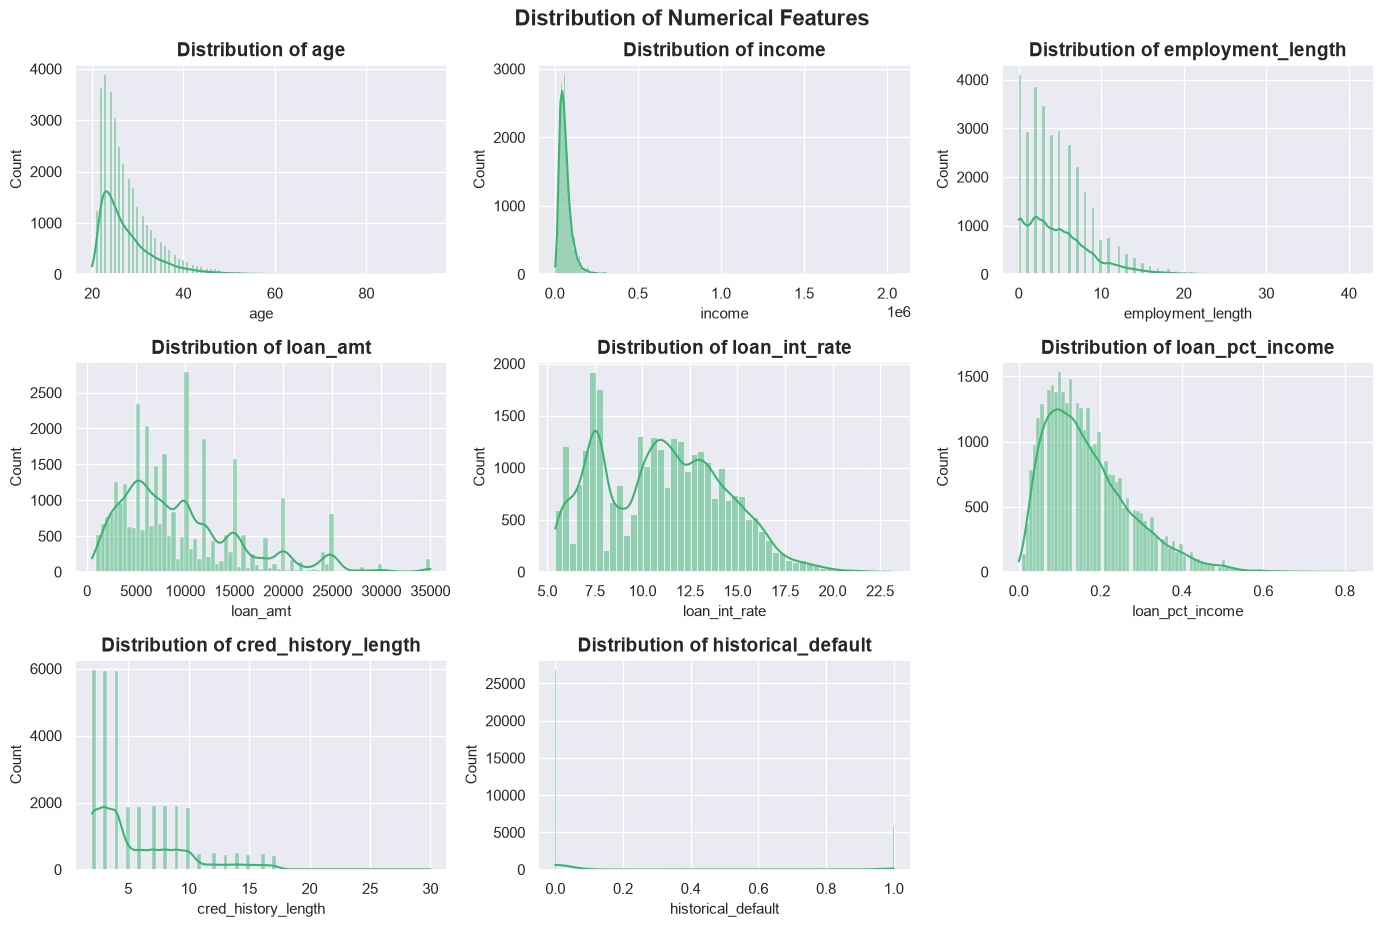

In [ ]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=3,
    figsize=(14, 3 * math.ceil(len(num_cols) / 2)),
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

All numerical variables are predominantly right-skewed

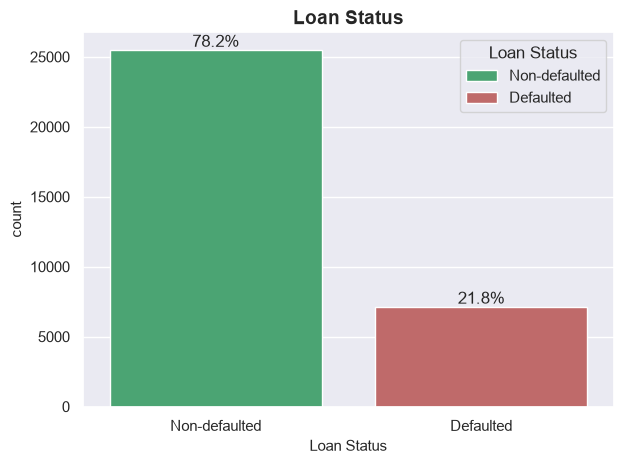

In [ ]:
ax = sns.countplot(data=df, x="loan_status", hue="loan_status")

for bar in ax.patches:
    if bar.get_height() == 0:
        continue
    pct = bar.get_height() / len(df) * 100
    ax.annotate(
        f"{pct:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Non-defaulted", "Defaulted"])
ax.set_xlabel("Loan Status")
ax.set_title("Loan Status")
ax.legend(title="Loan Status", labels=["Non-defaulted", "Defaulted"])
plt.tight_layout()
plt.show()

As expected, there is an imbalance with the data between 80% non-default and 20% defaulting clients. It is important to account for this moderate imbalance during modeling with techniques like stratifying the split.

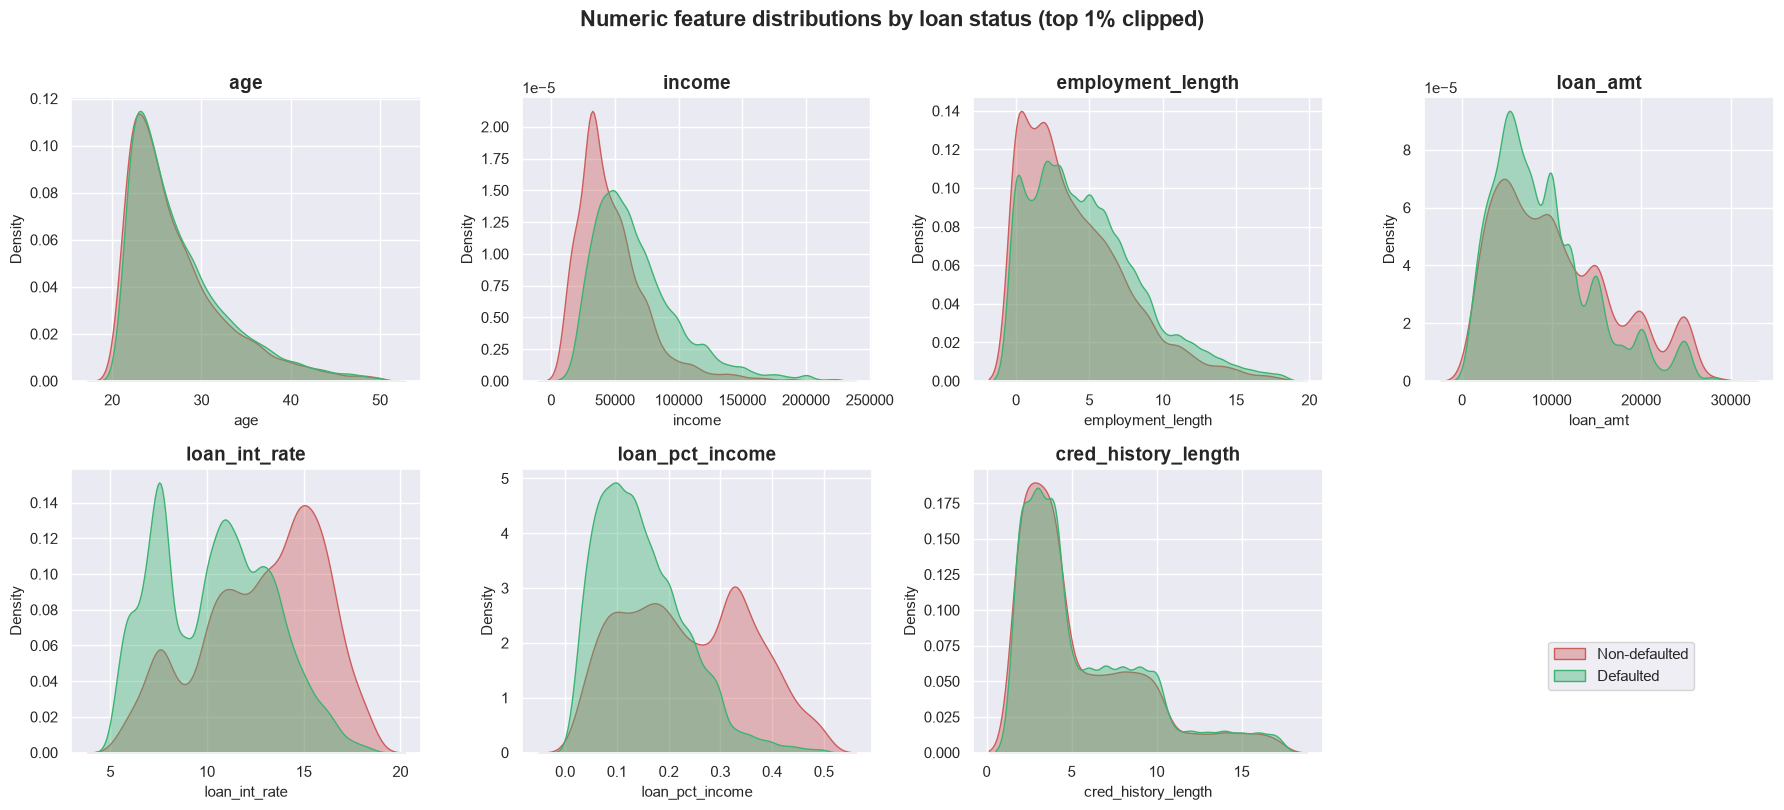

In [ ]:
num_cols = [
    "age",
    "income",
    "employment_length",
    "loan_amt",
    "loan_int_rate",
    "loan_pct_income",
    "cred_history_length",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    # clip the top 1% so outliers (income 2M, age 94) don't squash the plot
    upper = df[col].quantile(0.99)
    sns.kdeplot(
        data=df[df[col] <= upper],
        x=col,
        hue="loan_status",
        common_norm=False,
        fill=True,
        alpha=0.4,
        ax=ax,
        legend=False,
    )
    ax.set_title(col)

axes[-1].axis("off")  # unused 8th panel
fig.legend(
    ["Non-defaulted", "Defaulted"], loc="lower right", bbox_to_anchor=(0.95, 0.15)
)
plt.suptitle("Numeric feature distributions by loan status (top 1% clipped)", y=1.01)
plt.tight_layout()
plt.show()

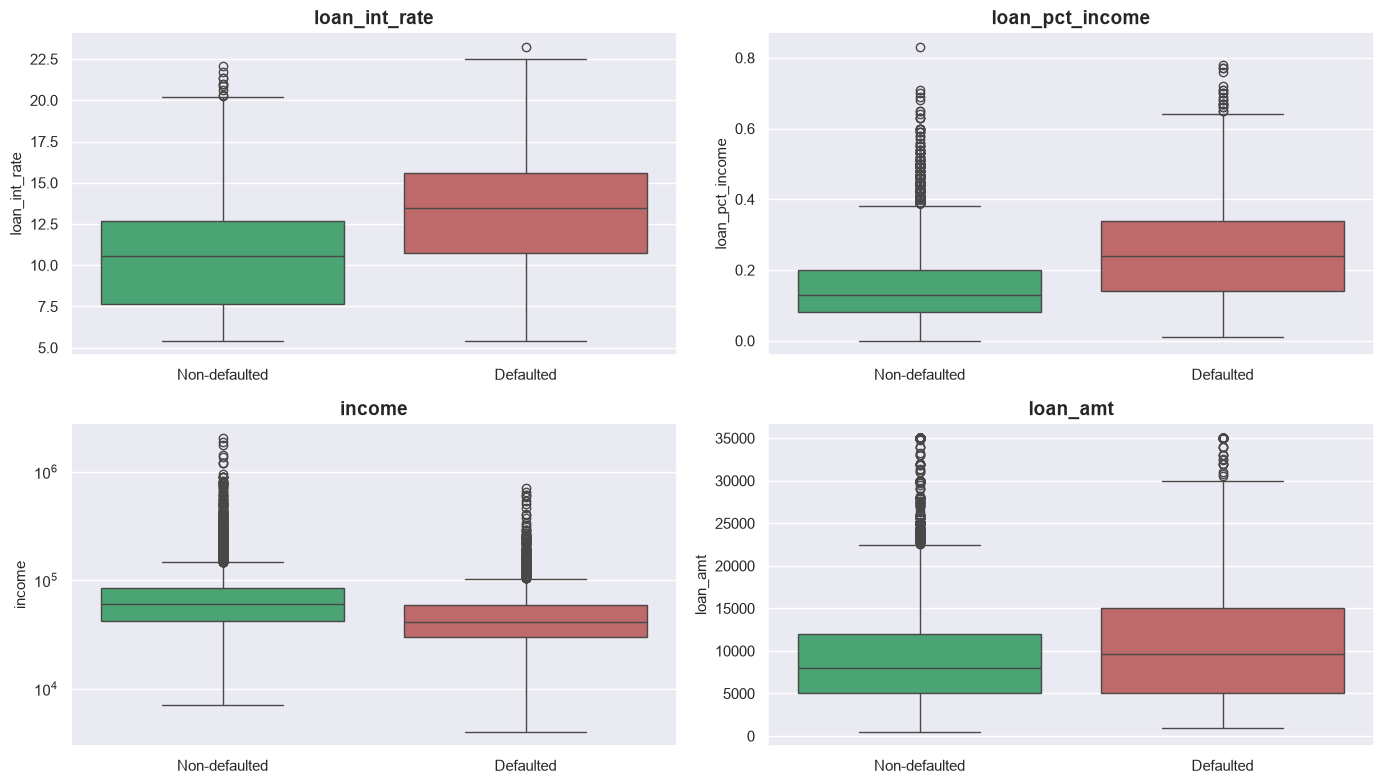

In [27]:
key_cols = ["loan_int_rate", "loan_pct_income", "income", "loan_amt"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, key_cols):
    sns.boxplot(data=df, x="loan_status", y=col, hue="loan_status", legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-defaulted", "Defaulted"])
    ax.set_xlabel("")
    ax.set_title(col)

axes[2].set_yscale("log")  # income is heavily right-skewed
plt.tight_layout()
plt.show()

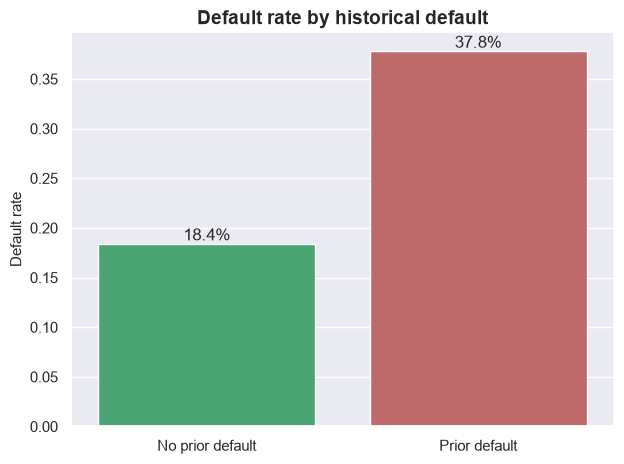

In [ ]:
ax = sns.barplot(
    data=df,
    x="historical_default",
    y="loan_status",
    hue="historical_default",
    legend=False,
    errorbar=None,
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height() * 100:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )

ax.set_xticks([0, 1])
ax.set_xticklabels(["No prior default", "Prior default"])
ax.set_xlabel("")
ax.set_ylabel("Default rate")
ax.set_title("Default rate by historical default")
plt.tight_layout()
plt.show()

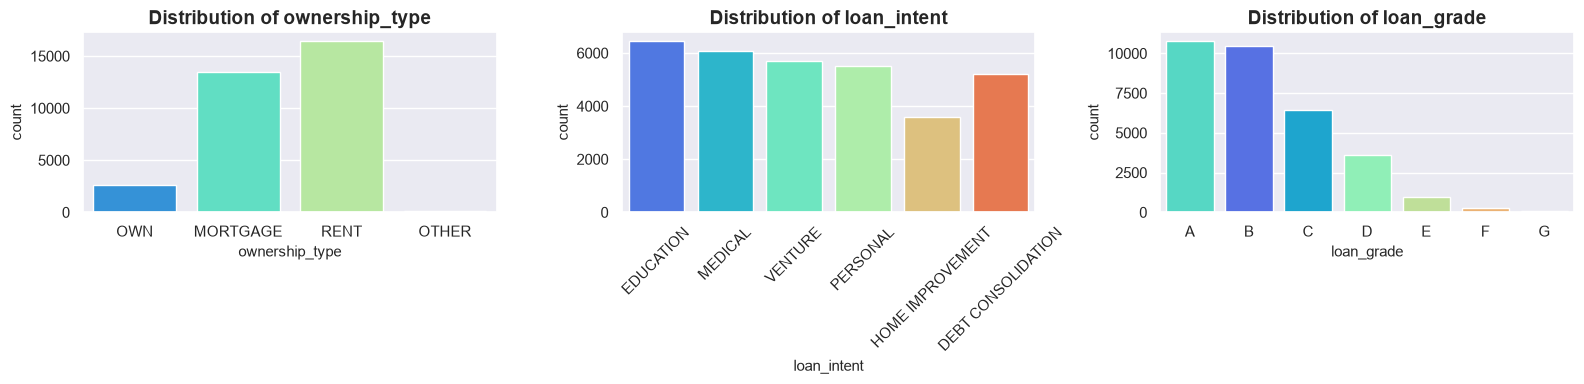

In [ ]:
cat_cols = df.select_dtypes(include=["object", "str", "category"]).columns.tolist()

fig, axes = plt.subplots(
    nrows=math.ceil(len(cat_cols) / 3),
    ncols=3,
    figsize=(16, 4 * math.ceil(len(cat_cols) / 3)),
)

axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = list("ABCDEFG") if col == "loan_grade" else None

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        order=order,
        palette="rainbow",
        hue=col,
        legend=False,
    )
    axes[i].set_title(f"Distribution of {col}")

    if col == "loan_intent":
        axes[i].tick_params(axis="x", rotation=45)

for i in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

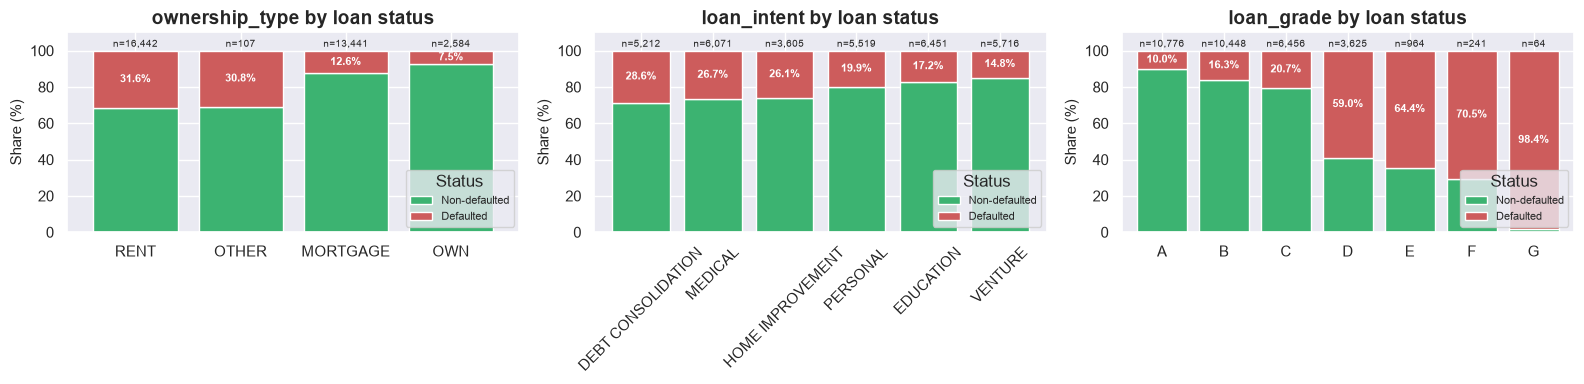

In [ ]:
n_rows = math.ceil(len(cat_cols) / 3)

fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df["loan_status"], normalize="index") * 100
    counts = df[col].value_counts()

    if col == "loan_grade":
        ct = ct.sort_index()
    else:
        ct = ct.sort_values(1, ascending=False)  # highest default rate first

    ct.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["mediumseagreen", "indianred"],
        width=0.8,
    )

    # label the default segment (and n) on each bar
    for i, idx in enumerate(ct.index):
        ax.text(
            i,
            ct.loc[idx, 0] + ct.loc[idx, 1] / 2,
            f"{ct.loc[idx, 1]:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=8,
            fontweight="bold",
        )
        ax.text(i, 101, f"n={counts[idx]:,}", ha="center", va="bottom", fontsize=7)

    ax.set_title(f"{col} by loan status")
    ax.set_xlabel("")
    ax.set_ylabel("Share (%)")
    ax.set_ylim(0, 110)
    ax.legend(
        title="Status",
        labels=["Non-defaulted", "Defaulted"],
        fontsize=8,
        loc="lower right",
    )
    ax.tick_params(axis="x", rotation=45 if col == "loan_intent" else 0)

for ax in axes[len(cat_cols) :]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

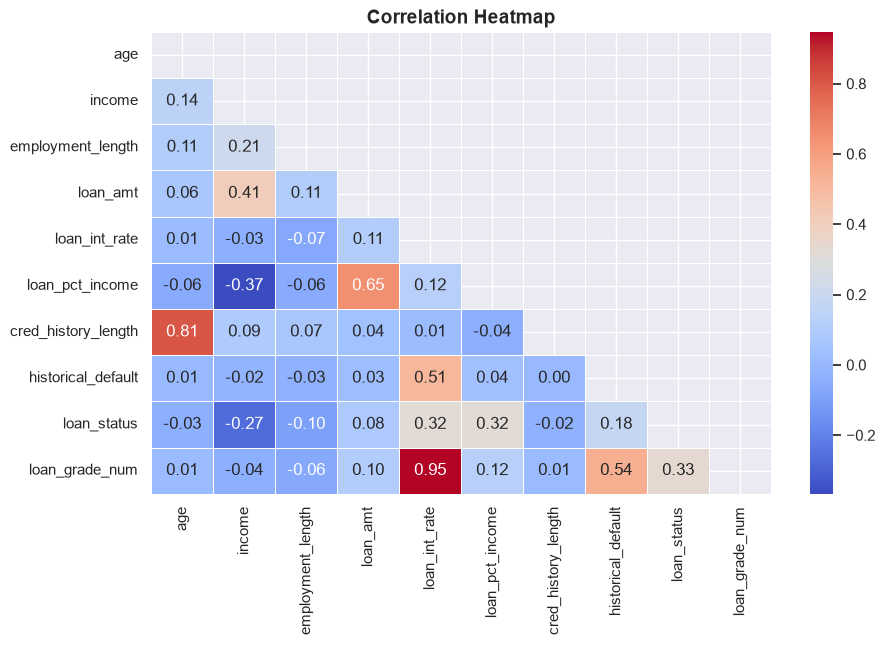

In [31]:
num_features = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

corr = num_features.corr(method="spearman")
matrix = np.triu(corr)

sns.heatmap(corr, mask=matrix, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Check for multicollinearity concerns later after scaling our inputs.

## Modeling

Stratifying into 70/15/15

In [32]:
X = df.drop(columns=["loan_status", "loan_grade"])
y = df["loan_status"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

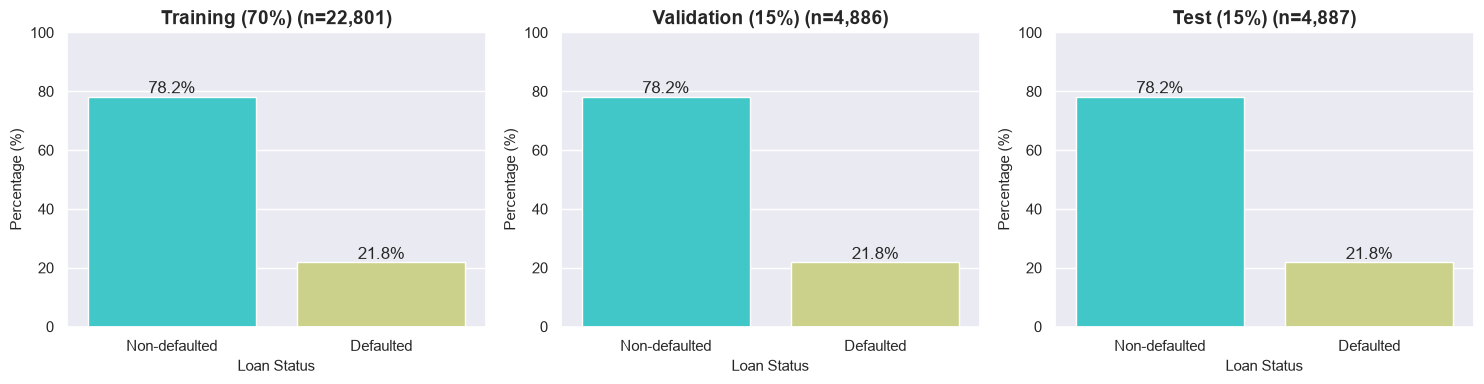

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, split, title in zip(
    axes, [y_train, y_val, y_test], ["Training (70%)", "Validation (15%)", "Test (15%)"]
):
    percentages = split.value_counts(normalize=True).sort_index() * 100

    sns.barplot(
        x=percentages.index,
        y=percentages.values,
        ax=ax,
        hue=percentages.index,
        palette="rainbow",
        legend=False,
    )

    for bar in ax.patches:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
        )

    ax.set_title(f"{title} (n={len(split):,})")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-defaulted", "Defaulted"])
    ax.set_xlabel("Loan Status")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [34]:
X.columns

Index(['age', 'income', 'employment_length', 'ownership_type', 'loan_intent',
       'loan_amt', 'loan_int_rate', 'loan_pct_income', 'cred_history_length',
       'historical_default', 'loan_grade_num'],
      dtype='str')

In [ ]:
num_cols = (
    df.select_dtypes(include="number")
    .columns.drop(target_col, errors="ignore")
    .tolist()
)
num_cols

['age',
 'income',
 'employment_length',
 'loan_amt',
 'loan_int_rate',
 'loan_pct_income',
 'cred_history_length',
 'historical_default',
 'loan_grade_num']

In [ ]:
skew = X_train[num_cols].skew().sort_values(ascending=False)

skew_df = pd.DataFrame({"skew": skew.map("{:.2f}".format), "> 1": skew.abs() > 1})
print(skew_df)

                     skew    > 1
income               8.08   True
age                  1.96   True
historical_default   1.69   True
cred_history_length  1.67   True
employment_length    1.24   True
loan_amt             1.21   True
loan_pct_income      1.07   True
loan_grade_num       0.86  False
loan_int_rate        0.20  False


In [ ]:
from sklearn.preprocessing import PowerTransformer

num_cols = [
    "age",
    "income",
    "employment_length",
    "loan_amt",
    "loan_int_rate",
    "loan_pct_income",
    "cred_history_length",
]

# before
before = X_train[num_cols].skew()

# after log1p
after_log = np.log1p(X_train[num_cols]).skew()

# after Yeo-Johnson (NaNs are ignored when fitting and left as NaN)
pt = PowerTransformer(method="yeo-johnson", standardize=False)
yj = pd.DataFrame(
    pt.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index
)
after_yj = yj.skew()

skew_df = pd.DataFrame(
    {
        "before": before,
        "log1p": after_log,
        "yeo-johnson": after_yj,
        "lambda": pt.lambdas_,
    }
).sort_values("before", ascending=False)

print(skew_df.round(2))

                     before  log1p  yeo-johnson  lambda
income                 8.08   0.14        -0.01   -0.06
age                    1.96   1.18         0.16   -2.53
cred_history_length    1.67   0.49         0.10   -0.51
employment_length      1.24  -0.46        -0.05    0.27
loan_amt               1.21  -0.44        -0.02    0.23
loan_pct_income        1.07   0.82         0.09   -3.85
loan_int_rate          0.20  -0.27        -0.04    0.50


#### 🔧 Preprocessing Pipeline

1. Categorical Features
    * Nominal: `ownership_type`, `loan_intent`
        * Chosen Imputer: SimpleImputer(strategy="constant", fill_value="Missing") - missing data will be kept as a true unknown 
        * Chosen Encoder: OneHotEncoder(drop="first", handle_unknown="ignore") - one-hot encoding preserves the absence of an order between types
2. Numerical Features
    * Correlated Age Variables: `age`, `employment_length`, `cred_history_length`
        * Chosen Imputer: IterativeImputer - Captures directional relationships between variables (like age and credit history length), making use of where related data is complete to impute the missing correlated data in a round robin fashion.
        * Chosen Transformer: log1p + StandardScaler - helps address predominantly skewed variables
    * Correlated Loan Rate + Grade Variable: `loan_int_rate` & `loan_grade_num`
        * Chosen Imputer: IterativeImputer
        * Chosen Transformer: StandardScaler only - lower skew values < 1
    * Other Num Features: `income`, `loan_pct_income`, `loan_amt`
        * Chosen Imputer: Median - robust to outliers
        * Chosen Transformer: log1p + StandardScaler - helps address predominantly skewed variables

`historical_default` passes through since it's already 0/1

In [ ]:
# # map grade A-G -> 1-7 before the pipeline (fixed rule, no leakage)
# grade_map = {g: i for i, g in enumerate("ABCDEFG", start=1)}
# for d in (X_train, X_val, X_test):
#     d["loan_grade_num"] = d["loan_grade"].map(grade_map)


def log1p_func(X):
    return np.log1p(X)


def make_log():
    return FunctionTransformer(log1p_func, feature_names_out="one-to-one")


cat_cols = ["ownership_type", "loan_intent"]
age_cols = ["age", "employment_length", "cred_history_length"]
rate_cols = ["loan_int_rate", "loan_grade_num"]
other_num_cols = ["income", "loan_pct_income", "loan_amt"]
bin_cols = ["historical_default"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline(
                [
                    (
                        "imputer",
                        SimpleImputer(strategy="constant", fill_value="Missing"),
                    ),
                    (
                        "encoder",
                        OneHotEncoder(
                            drop="first", handle_unknown="ignore", sparse_output=False
                        ),
                    ),
                ]
            ),
            cat_cols,
        ),
        (
            "num_ages",
            Pipeline(
                [
                    ("imputer", IterativeImputer(max_iter=10, random_state=42)),
                    ("fallback", SimpleImputer(strategy="median")),
                    ("log", make_log()),
                    ("scaler", StandardScaler()),
                ]
            ),
            age_cols,
        ),
        (
            "num_rates",
            Pipeline(
                [
                    ("imputer", IterativeImputer(max_iter=10, random_state=42)),
                    ("fallback", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            rate_cols,
        ),
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("log", make_log()),
                    ("scaler", StandardScaler()),
                ]
            ),
            other_num_cols,
        ),
        ("bi", SimpleImputer(strategy="most_frequent"), bin_cols),
    ],
    remainder="drop",
)

preprocessor.set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

#### VIF / Multicollinearity check

If there are highly multicollinear variables, there is possibly a need for more preprocessing as these can distort model estimates (inflated sensitivity and high variance). Multicollinearity can be computed via Variance Inflation Factor:  
* VIF values > 5 indicates moderate multicollinearity through inflated factors
* VIF > 10 indicates extreme multicollinearity

In [ ]:
X_const = add_constant(X_train_p.astype(float))

vif = pd.DataFrame(
    {
        "feature": X_train_p.columns,
        "VIF": [
            variance_inflation_factor(X_const.values, i + 1)
            for i in range(X_train_p.shape[1])
        ],
    }
).sort_values("VIF", ascending=False)

vif["VIF"] = vif["VIF"].round(2)
vif["> 5"] = vif["VIF"] > 5
print(vif)

                              feature   VIF    > 5
12          num_rates__loan_grade_num  8.93   True
11           num_rates__loan_int_rate  8.54   True
15                      num__loan_amt  7.93   True
14               num__loan_pct_income  7.73   True
13                        num__income  5.95   True
8                       num_ages__age  3.53  False
10      num_ages__cred_history_length  3.48  False
3          cat__loan_intent_EDUCATION  1.82  False
7            cat__loan_intent_VENTURE  1.78  False
5            cat__loan_intent_MEDICAL  1.78  False
6           cat__loan_intent_PERSONAL  1.73  False
4   cat__loan_intent_HOME IMPROVEMENT  1.53  False
16             bi__historical_default  1.41  False
2            cat__ownership_type_RENT  1.30  False
1             cat__ownership_type_OWN  1.17  False
9         num_ages__employment_length  1.08  False
0           cat__ownership_type_OTHER  1.01  False


### Model Training

* Default threshold of 0.5
*  ⭐ Star Metric: ROC AUC - mesauring ability of the model to rank good vs. bad accounts
    * Area under receiver operating curve
Measures discrimination at all thresholds
0.7+ acceptable; 0.9+ excellent
Guides approval thresholds for risk appetite
* Recall (Sensitivity / True Positive Rate)
    * Critical to catch bad loans early and minimize risks

#### Baseline model

In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_p, y_train)

results, new_results = score_predictions(
    dummy.predict_proba(X_train_p)[:, 1],
    dummy.predict_proba(X_val_p)[:, 1],
    y_train,
    y_val,
    "Baseline Dummy",
    {"strategy": "most_frequent"},
)
new_results

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,Baseline Dummy,0.5,0.0,0.0,0.0,0.218,{'strategy': 'most_frequent'}


In [ ]:
logreg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
)
logreg.fit(X_train_p, y_train)

proba_train = logreg.predict_proba(X_train_p)[:, 1]
proba_val = logreg.predict_proba(X_val_p)[:, 1]

results, new_results = score_predictions(
    proba_train,
    proba_val,
    y_train,
    y_val,
    "Baseline Logistic Regression",
    {"class_weight": "balanced", "max_iter": 1000},
    results=results,
)
new_results

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,Baseline Logistic Regression,0.868,0.789,0.62,0.511,0.705,"{'class_weight': 'balanced', 'max_iter': 1000}"
1,Baseline Dummy,0.500,0.000,0.00,0.000,0.218,{'strategy': 'most_frequent'}


In [ ]:
brf = BalancedRandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    max_features="sqrt",
    sampling_strategy="all",  # balance every class (default in recent versions)
    replacement=True,  # bootstrap with replacement
    n_jobs=-1,
    random_state=42,
)
brf.fit(X_train_p, y_train)

results, new_results = score_predictions(
    brf.predict_proba(X_train_p)[:, 1],
    brf.predict_proba(X_val_p)[:, 1],
    y_train,
    y_val,
    "Balanced Random Forest",
    {"n_estimators": 300, "min_samples_leaf": 5},
    results=results,
)
new_results

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,Balanced Random Forest,0.929,0.779,0.782,0.785,0.877,"{'n_estimators': 300, 'min_samples_leaf': 5}"
1,Baseline Logistic Regression,0.868,0.789,0.620,0.511,0.705,"{'class_weight': 'balanced', 'max_iter': 1000}"
2,Baseline Dummy,0.500,0.000,0.000,0.000,0.218,{'strategy': 'most_frequent'}


In [ ]:
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.6,
    random_state=42,
    verbose=-1,
)
lgbm.fit(
    X_train_p,
    y_train,
    eval_X=X_val_p,
    eval_y=y_val,
    eval_metric="average_precision",
)

results, new_results = score_predictions(
    lgbm.predict_proba(X_train_p)[:, 1],
    lgbm.predict_proba(X_val_p)[:, 1],
    y_train,
    y_val,
    "LightGBM",
    {"n_estimators": 500, "lr": 0.05, "num_leaves": 31},
    results=results,
)

In [ ]:
xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.6,
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb.fit(
    X_train_p,
    y_train,
    eval_set=[(X_val_p, y_val)],
    verbose=False,
)

results, new_results = score_predictions(
    xgb.predict_proba(X_train_p)[:, 1],
    xgb.predict_proba(X_val_p)[:, 1],
    y_train,
    y_val,
    "XGBoost",
    {"n_estimators": xgb.best_iteration + 1, "lr": 0.05, "max_depth": 5},
    results=results,
)

In [45]:
cat = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    auto_class_weights="Balanced",
    eval_metric="PRAUC",
    early_stopping_rounds=50,
    random_seed=42,
    verbose=0,
)
cat.fit(
    X_train_p,
    y_train,
    eval_set=(X_val_p, y_val),
)

results, new_results = score_predictions(
    cat.predict_proba(X_train_p)[:, 1],
    cat.predict_proba(X_val_p)[:, 1],
    y_train,
    y_val,
    "CatBoost",
    {"iterations": cat.get_best_iteration() + 1, "lr": 0.05, "depth": 6},
    results=results,
)
new_results

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,LightGBM,0.946,0.797,0.810,0.824,0.902,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."
1,XGBoost,0.946,0.799,0.799,0.799,0.899,"{'n_estimators': 494, 'lr': 0.05, 'max_depth': 5}"
2,CatBoost,0.945,0.793,0.816,0.841,0.901,"{'iterations': 705, 'lr': 0.05, 'depth': 6}"
3,Balanced Random Forest,0.929,0.779,0.782,0.785,0.877,"{'n_estimators': 300, 'min_samples_leaf': 5}"
4,Baseline Logistic Regression,0.868,0.789,0.620,0.511,0.705,"{'class_weight': 'balanced', 'max_iter': 1000}"
5,Baseline Dummy,0.500,0.000,0.000,0.000,0.218,{'strategy': 'most_frequent'}


### Tuning

In [ ]:
spw = (y_train == 0).sum() / (y_train == 1).sum()

fixed = {
    "LightGBM": {
        "learning_rate": 0.05,
        "class_weight": "balanced",
        "subsample_freq": 1,
        "n_jobs": -1,
        "verbose": -1,
    },
    "XGBoost": {
        "learning_rate": 0.05,
        "scale_pos_weight": spw,
        "tree_method": "hist",
        "n_jobs": -1,
        "verbosity": 0,
    },
    "CatBoost": {
        "learning_rate": 0.05,
        "auto_class_weights": "Balanced",
        "verbose": 0,
        "thread_count": -1,
    },
}

In [47]:
# best_params, studies = tune_models(
#     ["LightGBM", "XGBoost", "CatBoost"], X_train, y_train, preprocessor, n_trials=50
# )

# for name, params in best_params.items():
#     print(f"\n{name}")
#     for k, v in params.items():
#         print(f"  {k}: {v:.8f}" if isinstance(v, float) else f"  {k}: {v}")

Best trial: 16. Best value: 0.948903: 100%|██████████| 50/50 [05:32<00:00,  6.65s/it]
✅ LightGBM: best CV ROC-AUC = 0.9489
Best trial: 29. Best value: 0.949107: 100%|██████████| 50/50 [01:26<00:00,  1.74s/it]
✅ XGBoost: best CV ROC-AUC = 0.9491
Best trial: 35. Best value: 0.946794: 100%|██████████| 50/50 [08:35<00:00, 10.31s/it]
✅ CatBoost: best CV ROC-AUC = 0.9468

best_params = {
    "LightGBM": {
        "num_leaves": 28,
        "max_depth": 9,
        "min_child_samples": 24,
        "subsample": 0.9235,
        "colsample_bytree": 0.8466,
        "reg_lambda": 0.1473,
        "reg_alpha": 0.1400,
        "n_estimators": 472,
    },
    "XGBoost": {
        "max_depth": 5,
        "min_child_weight": 10,
        "subsample": 0.8965,
        "colsample_bytree": 0.7784,
        "gamma": 0.7326,
        "reg_lambda": 0.0063,
        "reg_alpha": 0.0119,
        "n_estimators": 511,
    },
    "CatBoost": {
        "depth": 4,
        "l2_leaf_reg": 1.5367,
        "random_strength": 1.7813,
        "bagging_temperature": 1.0791,
        "border_count": 254,
        "iterations": 999,
    },
}

Best trial: 30. Best value: 0.948006: 100%|██████████| 50/50 [01:37<00:00,  1.95s/it]
✅ XGBoost: best CV ROC-AUC = 0.9480
Best trial: 33. Best value: 0.946888: 100%|██████████| 50/50 [12:05<00:00, 14.50s/it]✅ CatBoost: best CV ROC-AUC = 0.9469

LightGBM
  learning_rate: 0.04574679
  num_leaves: 17
  max_depth: 5
  min_child_samples: 36
  subsample: 0.84307317
  colsample_bytree: 0.66416266
  reg_lambda: 0.01942762
  reg_alpha: 0.17365379
  n_estimators: 710

XGBoost
  learning_rate: 0.02131733
  max_depth: 6
  min_child_weight: 13
  subsample: 0.95504061
  colsample_bytree: 0.85027899
  gamma: 0.62945131
  reg_lambda: 0.02799010
  reg_alpha: 0.00210983
  n_estimators: 757

CatBoost
  learning_rate: 0.08922837
  depth: 5
  l2_leaf_reg: 8.31226521
  random_strength: 1.10666529
  bagging_temperature: 0.00420861
  border_count: 254
  iterations: 626

Catboost reaching 999 iterations

In [48]:
best_params = {
    "LightGBM": {
        "learning_rate": 0.04574679,
        "num_leaves": 17,
        "max_depth": 5,
        "min_child_samples": 36,
        "subsample": 0.84307317,
        "colsample_bytree": 0.66416266,
        "reg_lambda": 0.01942762,
        "reg_alpha": 0.17365379,
        "n_estimators": 710,
    },
    "XGBoost": {
        "learning_rate": 0.02131733,
        "max_depth": 6,
        "min_child_weight": 13,
        "subsample": 0.95504061,
        "colsample_bytree": 0.85027899,
        "gamma": 0.62945131,
        "reg_lambda": 0.02799010,
        "reg_alpha": 0.00210983,
        "n_estimators": 757,
    },
    "CatBoost": {
        "learning_rate": 0.08922837,
        "depth": 5,
        "l2_leaf_reg": 8.31226521,
        "random_strength": 1.10666529,
        "bagging_temperature": 0.00420861,
        "border_count": 254,
        "iterations": 626,
    },
}

In [ ]:
preprocessor.fit(X_train, y_train)
X_train_p = preprocessor.transform(X_train)
X_val_p = preprocessor.transform(X_val)

for name, params in best_params.items():
    model = model_classes[name](**params, random_state=42)
    model.fit(X_train_p, y_train)

    results, new_results = score_predictions(
        model.predict_proba(X_train_p)[:, 1],
        model.predict_proba(X_val_p)[:, 1],
        y_train,
        y_val,
        f"{name} (tuned)",
        params,
        results=results,
    )

new_results

0:	learn: 0.6045745	total: 4.07ms	remaining: 2.54s
1:	learn: 0.5392327	total: 7.91ms	remaining: 2.47s
2:	learn: 0.4872584	total: 11.7ms	remaining: 2.44s
3:	learn: 0.4470297	total: 15.4ms	remaining: 2.39s
4:	learn: 0.4146412	total: 18.8ms	remaining: 2.34s
5:	learn: 0.3890775	total: 22.4ms	remaining: 2.31s
6:	learn: 0.3700487	total: 25.8ms	remaining: 2.28s
7:	learn: 0.3542329	total: 29.4ms	remaining: 2.27s
8:	learn: 0.3402793	total: 33ms	remaining: 2.26s
9:	learn: 0.3254762	total: 36.4ms	remaining: 2.24s
10:	learn: 0.3142544	total: 40.1ms	remaining: 2.24s
11:	learn: 0.3047447	total: 43.7ms	remaining: 2.24s
12:	learn: 0.2966731	total: 47.1ms	remaining: 2.22s
13:	learn: 0.2911288	total: 50.5ms	remaining: 2.21s
14:	learn: 0.2861178	total: 53.8ms	remaining: 2.19s
15:	learn: 0.2821658	total: 57.6ms	remaining: 2.2s
16:	learn: 0.2793603	total: 61.4ms	remaining: 2.2s
17:	learn: 0.2752301	total: 65.3ms	remaining: 2.21s
18:	learn: 0.2710284	total: 69.3ms	remaining: 2.21s
19:	learn: 0.2669245	total

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,LightGBM,0.946,0.797,0.810,0.824,0.902,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."
1,LightGBM (tuned),0.946,0.735,0.831,0.956,0.899,"{'learning_rate': 0.04574679, 'num_leaves': 17..."
2,XGBoost,0.946,0.799,0.799,0.799,0.899,"{'n_estimators': 494, 'lr': 0.05, 'max_depth': 5}"
3,CatBoost,0.945,0.793,0.816,0.841,0.901,"{'iterations': 705, 'lr': 0.05, 'depth': 6}"
4,CatBoost (tuned),0.944,0.735,0.835,0.966,0.901,"{'learning_rate': 0.08922837, 'depth': 5, 'l2_..."
5,XGBoost (tuned),0.943,0.731,0.828,0.956,0.897,"{'learning_rate': 0.02131733, 'max_depth': 6, ..."
6,Balanced Random Forest,0.929,0.779,0.782,0.785,0.877,"{'n_estimators': 300, 'min_samples_leaf': 5}"
7,Baseline Logistic Regression,0.868,0.789,0.620,0.511,0.705,"{'class_weight': 'balanced', 'max_iter': 1000}"
8,Baseline Dummy,0.500,0.000,0.000,0.000,0.218,{'strategy': 'most_frequent'}


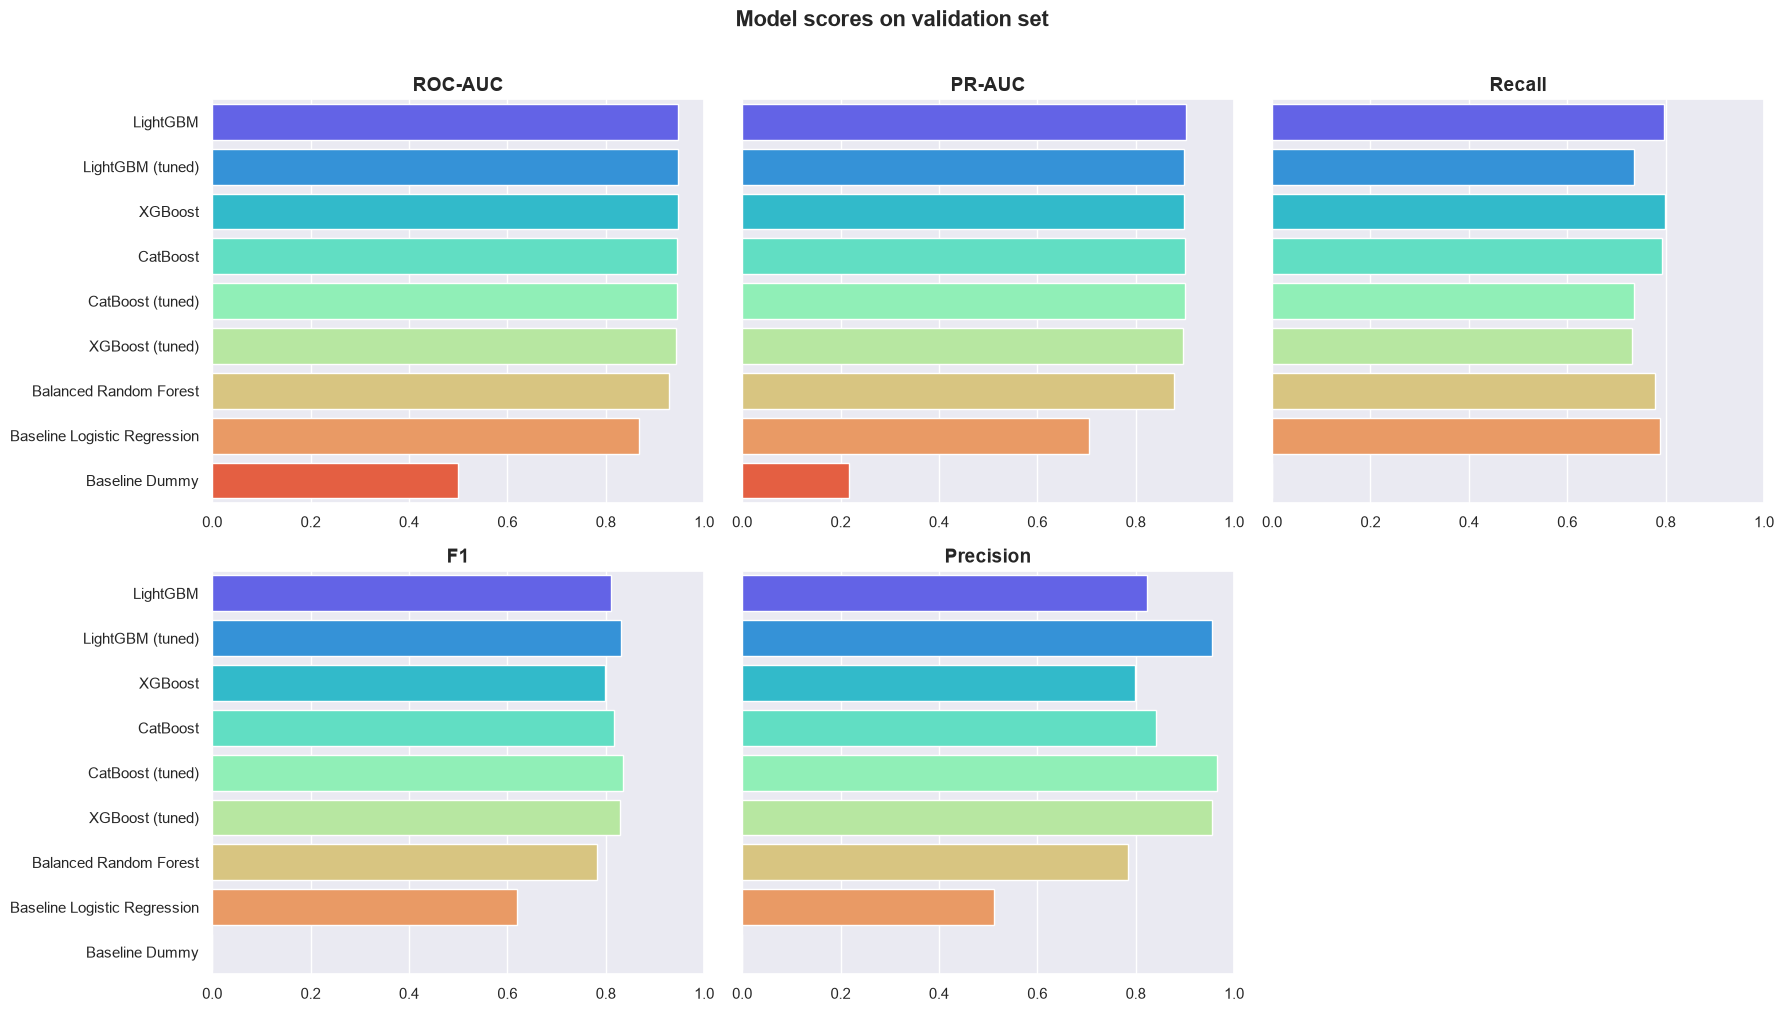

In [ ]:
metrics = ["ROC-AUC", "PR-AUC", "Recall", "F1", "Precision"]
order = new_results["Model"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=new_results,
        y="Model",
        x=metric,
        hue="Model",
        order=order,
        palette="rainbow",
        legend=False,
        ax=ax,
    )
    ax.set_xlim(0, 1.0)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax not in (axes[0], axes[3]):
        ax.set_yticklabels([])  # model names only on the left column

fig.delaxes(axes[5])
fig.suptitle("Model scores on validation set", y=1.01)
plt.tight_layout()
plt.show()

### Final Model

In [51]:
# 1. Refit the untuned LightGBM exactly as before (the `model` variable was overwritten)
final_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.6,
    random_state=42,
    verbose=-1,
)
final_model.fit(X_train_p, y_train)

,learning_rate,0.05
,n_estimators,500
,min_child_samples,50
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,scale_pos_weight,3.6
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1


In [ ]:
X_test_p = preprocessor.transform(X_test)

test_results, test_table = score_predictions(
    final_model.predict_proba(X_train_p)[:, 1],
    final_model.predict_proba(X_test_p)[:, 1],
    y_train,
    y_test,
    "LightGBM (final, test)",
    {
        "n_estimators": 500,
        "lr": 0.05,
        "num_leaves": 31,
        "min_child_samples": 50,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "scale_pos_weight": 3.6,
    },
    results=None,
)
test_table

,Model,ROC-AUC,Recall,F1,Precision,PR-AUC,Params
0,"LightGBM (final, test)",0.945,0.792,0.806,0.821,0.898,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."


Show mistakes
Show curve

## Feature Importance - SHAP

Conducting feature importance from n=2,000 sample to understand what customer and loan features are most telling for defaulting probabilities.

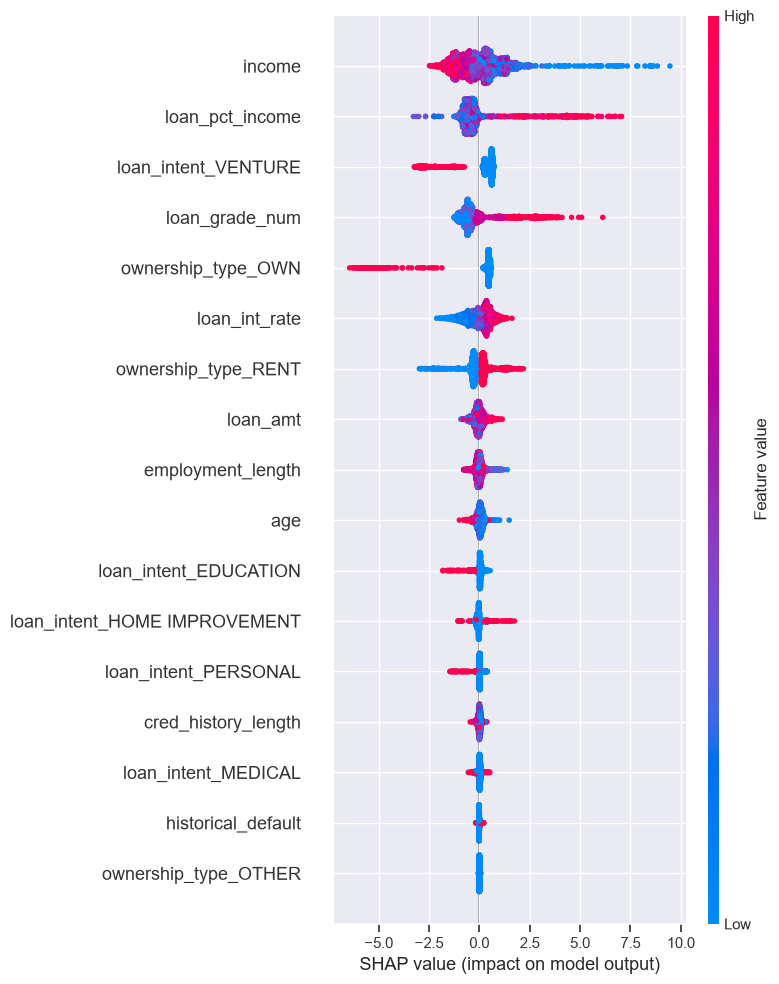

In [ ]:
import shap

explainer = shap.TreeExplainer(final_model)  # the untuned LightGBM, fit on X_train_p

sample_size = min(2000, len(X_test))
X_test_sample = X_test.sample(n=sample_size, random_state=42).reset_index(drop=True)
X_test_transformed = preprocessor.transform(X_test_sample)

shap_values = explainer(X_test_transformed)

# some shap/model versions return one slice per class; keep the "default" class
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

feature_names = preprocessor.get_feature_names_out()
feature_names_clean = [name.split("__")[-1] for name in feature_names]

shap.summary_plot(
    shap_values.values,
    X_test_transformed,
    feature_names=feature_names_clean,
    plot_size=(8, 10),
)

#### Sample predictions

Most risky: sample row 969 | P(default) = 100.0% | actual: Defaulted


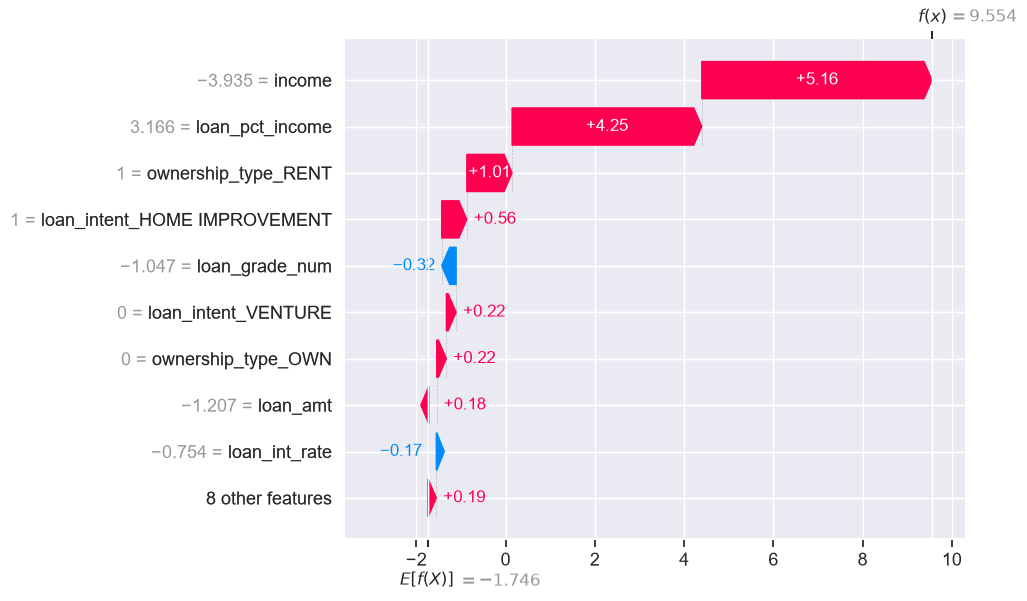

Least risky: sample row 145 | P(default) = 0.0% | actual: Non-defaulted


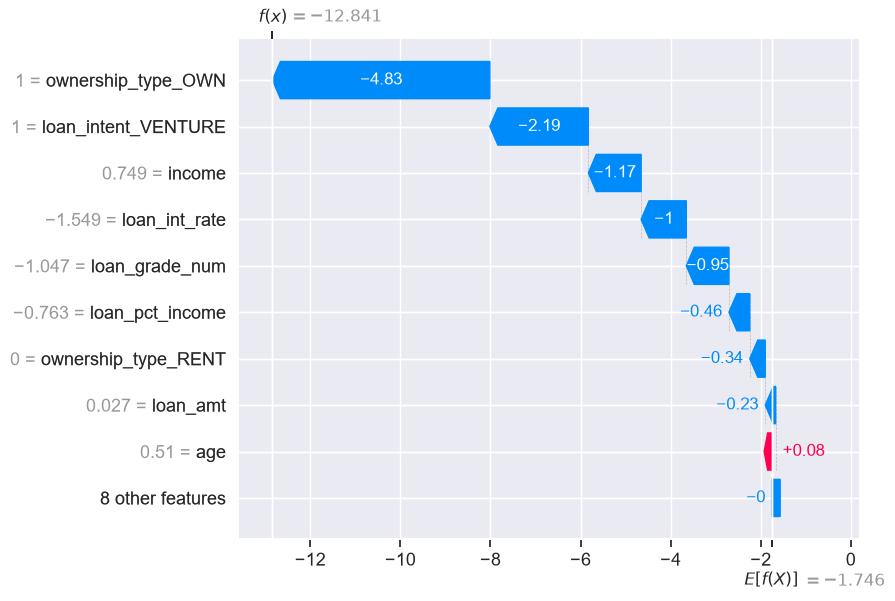

Random: sample row 178 | P(default) = 11.2% | actual: Non-defaulted


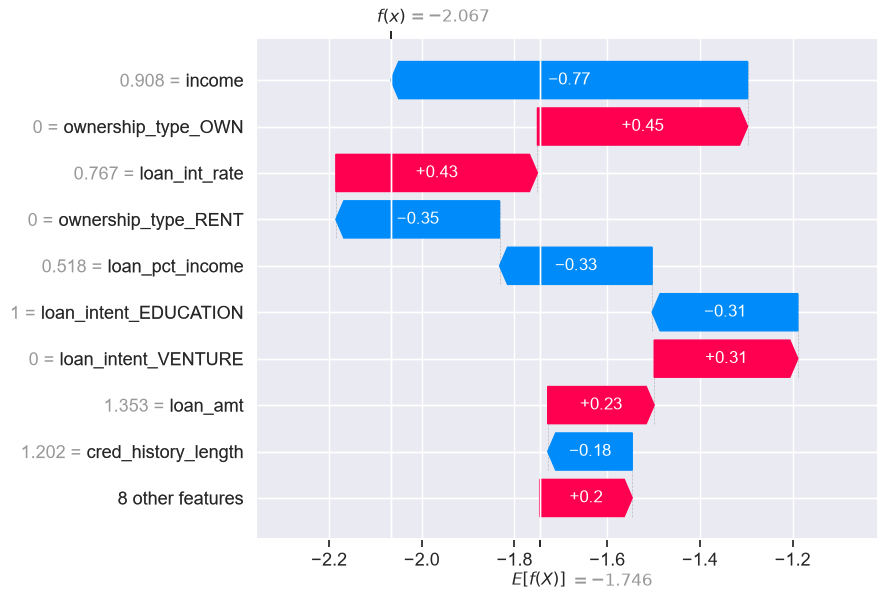

In [ ]:
proba = final_model.predict_proba(X_test_transformed)[:, 1]

# labels aligned to the shuffled sample (same random_state as the sample)
y_test_sample = y_test.loc[
    X_test.sample(n=sample_size, random_state=42).index
].reset_index(drop=True)

picks = {
    "Most risky": int(np.argmax(proba)),
    "Least risky": int(np.argmin(proba)),
    "Random": int(np.random.default_rng(42).integers(len(proba))),
}

for title, idx in picks.items():
    shap_exp = shap.Explanation(
        values=shap_values.values[idx],
        base_values=shap_values.base_values[idx],
        data=shap_values.data[idx],
        feature_names=feature_names_clean,
    )
    actual = "Defaulted" if y_test_sample.iloc[idx] == 1 else "Non-defaulted"
    print(
        f"{title}: sample row {idx} | P(default) = {proba[idx]:.1%} | actual: {actual}"
    )
    shap.plots.waterfall(shap_exp, max_display=10)

#### Customers at most risk

In [55]:
X_test_full_p = preprocessor.transform(X_test)
proba_test = final_model.predict_proba(X_test_full_p)[:, 1]

risk = X_test.copy()
risk["P(default)"] = proba_test
risk["Actual"] = y_test.map({0: "Non-defaulted", 1: "Defaulted"})

top10 = risk.sort_values("P(default)", ascending=False).head(10)
top10["P(default)"] = top10["P(default)"].map("{:.1%}".format)

top10

,age,income,employment_length,ownership_type,loan_intent,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_grade_num,P(default),Actual
8555,22,14400,3.0,RENT,HOME IMPROVEMENT,8000,9.99,0.56,4,0,2,100.0%,Defaulted
27895,29,6000,0.0,RENT,HOME IMPROVEMENT,3250,8.59,0.54,9,0,1,100.0%,Defaulted
18364,28,56000,0.0,RENT,MEDICAL,20000,18.62,0.36,7,0,6,100.0%,Defaulted
10073,25,19200,1.0,RENT,VENTURE,9500,7.88,0.49,4,0,1,100.0%,Defaulted
6073,23,12000,0.0,RENT,PERSONAL,5825,6.62,0.49,4,0,1,100.0%,Defaulted
7441,22,12000,0.0,RENT,EDUCATION,6700,7.66,0.56,4,0,1,100.0%,Defaulted
7035,22,16000,NaN,RENT,VENTURE,6250,9.91,0.39,2,0,2,100.0%,Defaulted
3470,22,20796,1.0,RENT,DEBT CONSOLIDATION,10775,15.37,0.52,2,1,4,100.0%,Defaulted
6107,24,16800,2.0,RENT,DEBT CONSOLIDATION,6000,14.84,0.36,4,1,4,100.0%,Defaulted
31829,39,49000,0.0,RENT,DEBT CONSOLIDATION,15175,19.13,0.31,11,1,6,100.0%,Defaulted


## Conclusion

* Threshold tuning
* Top n cases

Feature roadmap / to-add:
* Threshold tuning
* Ready for deployment
